In [1]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)

import torch

import numpy as np
import pandas as pd

import umap
import matplotlib.pyplot as plt

from lib_models import ConvVAE, BagVariationalEncoder, make_splits, read_from_summary, extract
from lib_linear_probing import run_nn_probes
from sklearn.decomposition import PCA

https://apxml.com/courses/applied-autoencoders-feature-extraction/chapter-7-applying-autoencoder-features-practical-guidance/tuning-hyperparameters-optimal-performance

In [2]:
run_name = "convvae_l256_k3-3s1p1_h32-64_bn1_bs10_mi150_beta0.1_ann20"
out_dir = f"results_s00/{run_name}"
dev_path = "splits/s00_developmental.npz"

split_k = 5                        # AE split: test fold = k, val fold = k+1, rest = train
seed = 42
representations = ["trained_ae", "untrained_ae", "pca", "raw"]

hp, ckpt = read_from_summary(out_dir, split_k)

In [3]:
with np.load(dev_path) as s:
    dev_folds = [s[f"fold_{k}"] for k in range(len(s.files))]

_, train_idx, val_idx, test_idx = next(split for split in make_splits(dev_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

splits = [("train", train_idx), ("val", val_idx), ("test", test_idx)]
raw = {n: extract(i) for n, i in splits}  # (bags, labels), raw flattened windows
y_train, y_val, y_test = raw["train"][1], raw["val"][1], raw["test"][1]

print("pathology rate  train/val/test:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

train=1087  val=132  test=134
pathology rate  train/val/test: 0.482 0.447 0.485


In [4]:
def build_ae(hp):
    return ConvVAE(latent=hp["latent"], kernel=hp["kernel"], strides=hp["strides"],
                  padding=hp["padding"], batchnorm=hp["batchnorm"], hidden=hp["hidden"])
def mu_encoder(vae):
    """Window -> posterior mean. ConvVAE.encoder alone returns flattened conv features, not the latent."""
    return lambda x: vae.fc_mu(vae.encoder(x))

trained_vae = BagVariationalEncoder.load_from_checkpoint(ckpt, ae=build_ae(hp), map_location="cpu").eval()

torch.manual_seed(seed)                      
random_vae = build_ae(hp).eval()        

In [5]:
bags = {"raw": {n: raw[n][0] for n in raw}}
for name, encoder in [("trained_ae", mu_encoder(trained_vae.ae)),
                      ("untrained_ae", mu_encoder(random_vae))]:
        bags[name] = {n: extract(i, encoder)[0] for n, i in splits}

In [6]:
pca = PCA(n_components=hp["latent"], random_state=seed).fit(np.concatenate(bags["raw"]["train"]))
bags["pca"] = {n: [pca.transform(b) for b in bl] for n, bl in bags["raw"].items()}

In [7]:
for representation, data_part in bags.items():
    print(f"{representation:7s} bag shape (windows, dim) = {data_part['train'][0].shape}")

raw     bag shape (windows, dim) = (150, 1445)
trained_ae bag shape (windows, dim) = (150, 256)
untrained_ae bag shape (windows, dim) = (150, 256)
pca     bag shape (windows, dim) = (150, 256)


In [8]:
reducer = umap.UMAP()

In [9]:
val_instances_trained = np.concatenate(bags["trained_ae"]["val"], axis = 0)
val_instances_untrained = np.concatenate(bags["untrained_ae"]["val"], axis = 0)
val_instances_raw = np.concatenate(bags["raw"]["val"], axis = 0)
val_instances_pca = np.concatenate(bags["pca"]["val"], axis = 0)

In [10]:
val_bags = bags["trained_ae"]["val"]
exam_ids = np.repeat(np.arange(len(val_bags)), [len(bag) for bag in val_bags])
bag_sizes = [len(bag) for bag in val_bags]
window_labels = np.repeat(np.asarray(y_val).ravel(), bag_sizes)

In [11]:
val_bags = bags["trained_ae"]["val"]
exam_ids = np.repeat(np.arange(len(val_bags)), [len(bag) for bag in val_bags])
bag_sizes = [len(bag) for bag in val_bags]
window_labels = np.repeat(np.asarray(y_val).ravel(), bag_sizes)

embeddings = {
    "trained":   reducer.fit_transform(val_instances_trained),
    "untrained": reducer.fit_transform(val_instances_untrained),
    "raw":       reducer.fit_transform(val_instances_raw),
    "pca":       reducer.fit_transform(val_instances_pca),
}

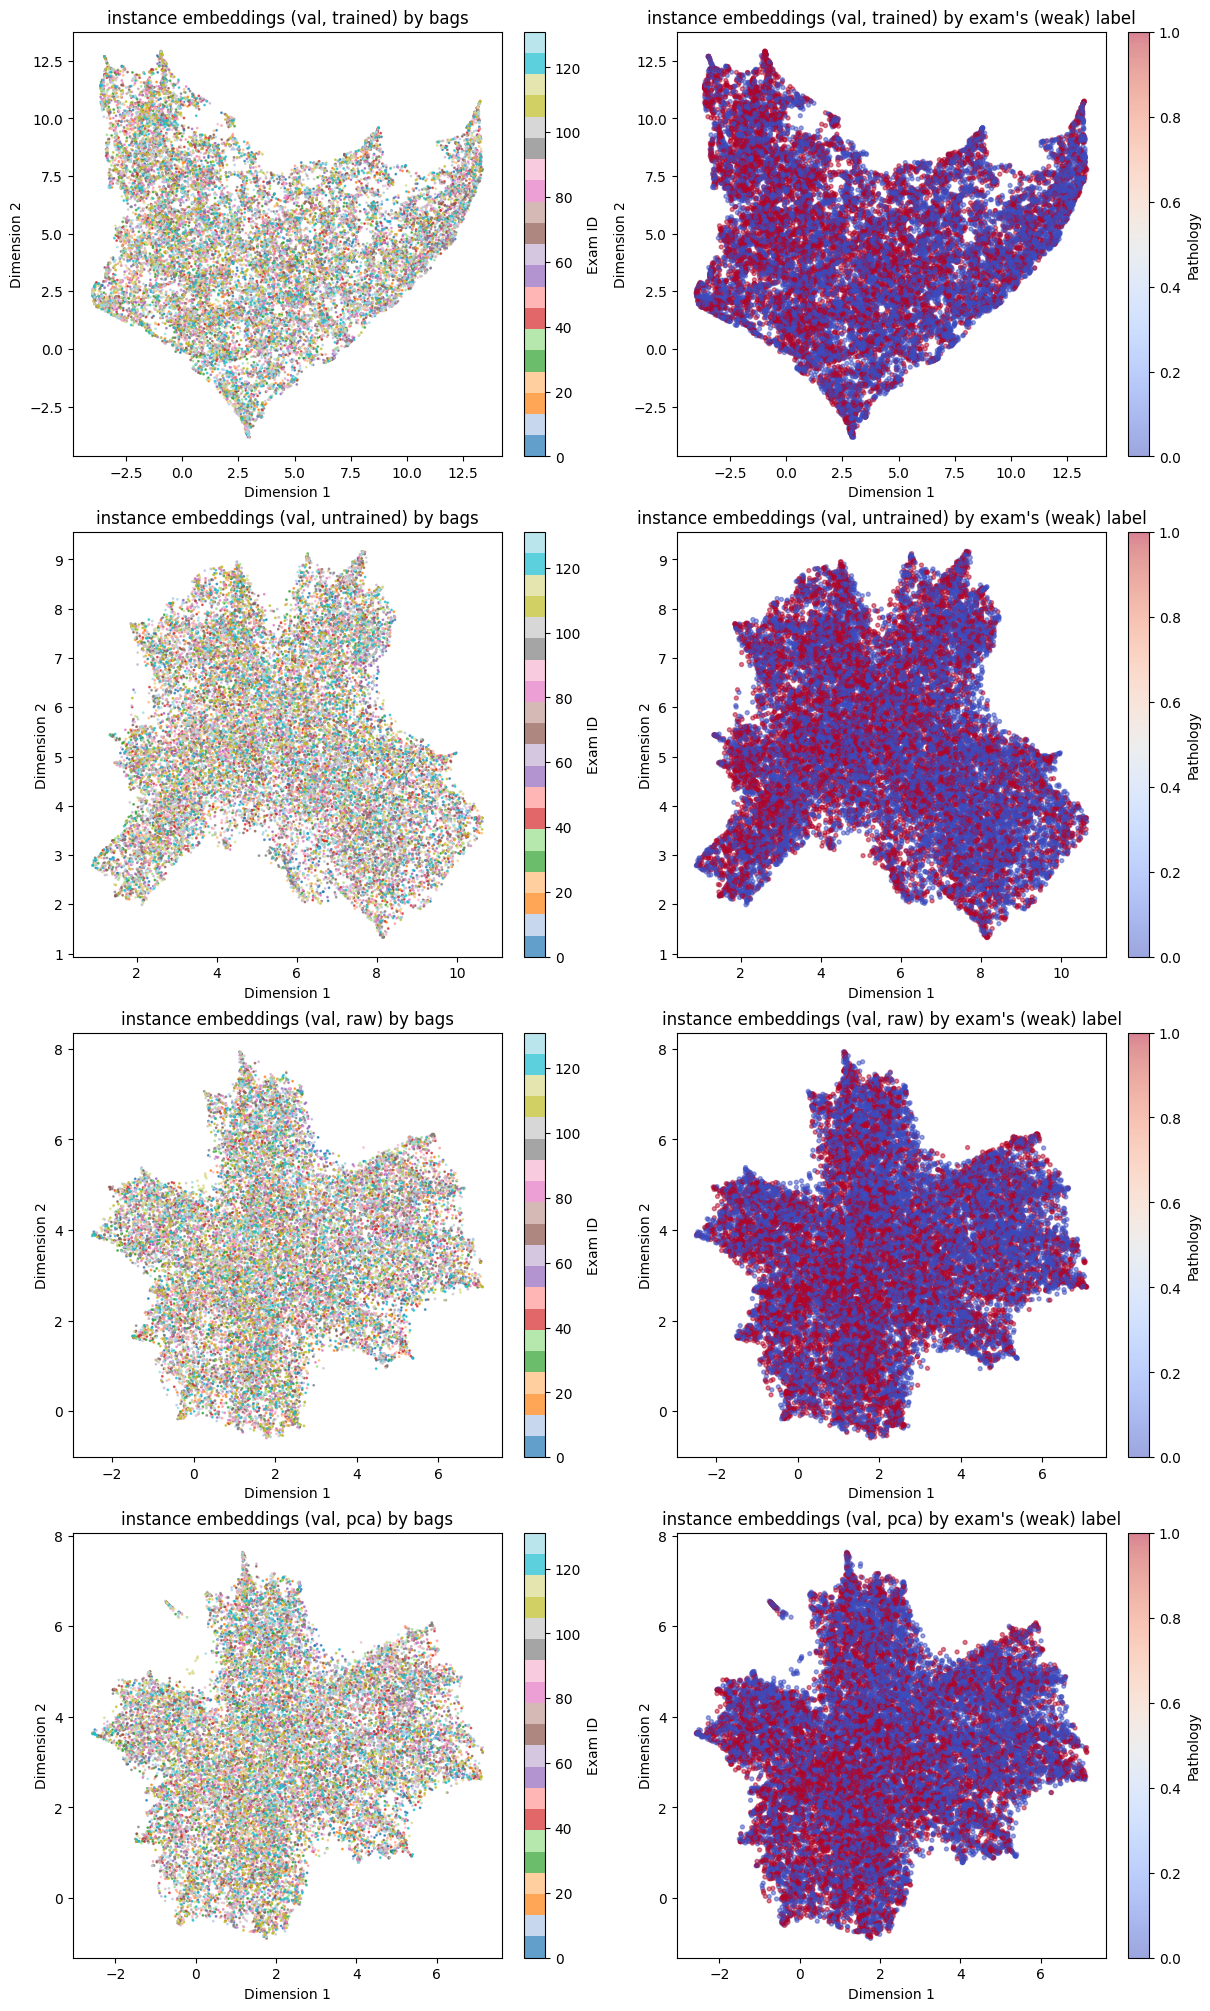

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(12, 20), constrained_layout=True)

for row, (name, embedding) in enumerate(embeddings.items()):

    ax = axes[row, 0]
    scatter = ax.scatter(embedding[:, 0], #type:ignore
                    embedding[:, 1],  #type:ignore
                    c=exam_ids, 
                    cmap="tab20", 
                    s=1, 
                    alpha=0.7, 
                    rasterized=True)
    
    ax.set_title(f"instance embeddings (val, {name}) by bags")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    fig.colorbar(scatter, ax=ax, label="Exam ID")


    ax = axes[row, 1]
    scatter = ax.scatter(embedding[:, 0], #type:ignore
                    embedding[:, 1], #type:ignore
                    c=window_labels, 
                    cmap="coolwarm", 
                    s=8, 
                    alpha=0.5, 
                    rasterized=True)
    
    ax.set_title(f"instance embeddings (val, {name}) by exam's (weak) label")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    fig.colorbar(scatter, ax=ax, label="Pathology")

plt.show()

In [13]:
rows = run_nn_probes(bags, representations, y_train, y_val, y_test,
                         lr=1e-3,
                         batch_size=100,
                         max_epochs=200)

[trained_ae] LinearBagProbe  val AUC = 0.659  epoch = 83  test AUC = 0.661
[trained_ae] LinearInstanceProbeBagLabels_soft  val AUC = 0.703  epoch = 51  test AUC = 0.618
[trained_ae] LinearInstanceProbeBagLabels_vote  val AUC = 0.635  epoch = 51  test AUC = 0.616
[untrained_ae] LinearBagProbe  val AUC = 0.698  epoch = 34  test AUC = 0.692
[untrained_ae] LinearInstanceProbeBagLabels_soft  val AUC = 0.710  epoch = 5  test AUC = 0.662
[untrained_ae] LinearInstanceProbeBagLabels_vote  val AUC = 0.713  epoch = 5  test AUC = 0.661
[pca] LinearBagProbe  val AUC = 0.690  epoch = 12  test AUC = 0.650
[pca] LinearInstanceProbeBagLabels_soft  val AUC = 0.677  epoch = 2  test AUC = 0.656
[pca] LinearInstanceProbeBagLabels_vote  val AUC = 0.698  epoch = 2  test AUC = 0.655
[raw] LinearBagProbe  val AUC = 0.705  epoch = 4  test AUC = 0.635
[raw] LinearInstanceProbeBagLabels_soft  val AUC = 0.689  epoch = 14  test AUC = 0.639
[raw] LinearInstanceProbeBagLabels_vote  val AUC = 0.719  epoch = 14  test A

In [14]:
res_df = pd.DataFrame(rows).set_index(["Representation", "Method"])
res_df
#res_df.to_csv(f"{out_dir}/probe_results/{split_k}.csv", index = False)

Val AUC  Epoch  Test AUC
Representation Method                                                      
trained_ae     LinearBagProbe                     0.658927     83  0.661315
               LinearInstanceProbeBagLabels_soft  0.703274     51  0.617837
               LinearInstanceProbeBagLabels_vote  0.634548     51  0.616165
untrained_ae   LinearBagProbe                     0.698166     34  0.692308
               LinearInstanceProbeBagLabels_soft  0.710471      5  0.661761
               LinearInstanceProbeBagLabels_vote  0.712909      5  0.660535
pca            LinearBagProbe                     0.690272     12  0.650167
               LinearInstanceProbeBagLabels_soft  0.676573      2  0.656187
               LinearInstanceProbeBagLabels_vote  0.697701      2  0.654849
raw            LinearBagProbe                     0.704899      4  0.635229
               LinearInstanceProbeBagLabels_soft  0.688879     14  0.638573
               LinearInstanceProbeBagLabels_vote  0.719410     14  0.640914